# Salud / Farmaceutica / Biotech
Sector analizado: **Salud / Farmaceutica / Biotech**
- Tickers: UNH, PFE, ABBV, ABT, AMGN, GILD, LLY, BMY, MRK, AZN, GSK, CVS, MOH, DHR, IBB
- Mismo modelo de pesos y ranking que el cuaderno base.

In [1]:
import pandas as pd
import math
from datetime import datetime as _dt, timedelta as _]td
from functools import lru_cache
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
try:
    import seaborn as sns
except ImportError:
    raise ImportError("Debe instalar el paquete seaborn: pip install seaborn")
try:
    import yfinance as yf
except ImportError:
    raise ImportError("Debe instalar el paquete yfinance: pip install yfinance")

SyntaxError: unmatched ']' (1873735122.py, line 3)

Modelo Calibrado con:
-   "Market Cap": 0.05,
-   "P/E": 0.25,
-   "EPS": 0.10,
-   "EPS Growth": 0.05,
-   "Debt to Equity": 0.25,
-   "ROE": 0.05,
-   "ROEvar": 0.05,
-   "Roic/WACC": 0.20

Funciones para el ETA

In [2]:
def _to_numeric_series(s):
    """Devuelve la serie como float, coercionando strings/objetos a NaN cuando no sean numéricos."""
    if s is None:
        return pd.Series(dtype=float)
    try:
        return pd.to_numeric(pd.Series(s), errors="coerce")
    except Exception:
        try:
            # Si ya es una Series, coercionar directamente
            return pd.to_numeric(s, errors="coerce")
        except Exception:
            return pd.Series(dtype=float)
        

def _first_valid_float(s):
    """Primero válido y finito como float, o None."""
    try:
        s = _to_numeric_series(s).dropna()
        for v in s:
            if np.isfinite(v):
                return float(v)
        return None
    except Exception:
        return None
    
def _as_float(x):
    """Convierte cualquier valor a float finito si es posible; caso contrario devuelve np.nan."""
    try:
        v = float(x)
        return v if np.isfinite(v) else np.nan
    except Exception:
        # intentá remover separadores comunes
        try:
            v = float(str(x).replace(",", "").replace(" ", ""))
            return v if np.isfinite(v) else np.nan
        except Exception:
            return np.nan
        

def _finite_or_none(x):
    """Devuelve float(x) si es finito; si no, None."""
    v = _as_float(x)
    return None if (isinstance(v, float) and not np.isfinite(v)) or pd.isna(v) else v

def _bound(x, lo=None, hi=None):
    """Acota x entre [lo, hi] si corresponde."""
    v = _as_float(x)
    if pd.isna(v):
        return np.nan
    if lo is not None:
        v = max(lo, v)
    if hi is not None:
        v = min(hi, v)
    return v

Modelo 2

In [3]:
# ========= Helpers WACC (con chequeos)
def _latest_non_na(series):
    try:
        s = _to_numeric_series(series).dropna()
        return float(s.iloc[0]) if len(s) else None
    except Exception:
        return None


def _fetch_risk_free_rate():
    try:
        tnx = yf.Ticker("^TNX").history(period="5d", interval="1d")
        if tnx is None or tnx.empty:
            return None
        val = _as_float(tnx["Close"].iloc[-1]) / 100.0
        return _finite_or_none(val)
    except Exception:
        return None


def _compute_tax_rate(income):
    if income is None or getattr(income, "empty", True):
        return None
    tax_names = ["Income Tax Expense","Provision for Income Taxes","Tax Provision","Income Tax Expense Benefit"]
    ebt_names = ["Income Before Tax","Earnings Before Tax","Pretax Income","Income Before Tax (EBT)"]
    tax = ebt = None
    for n in tax_names:
        if n in income.index:
            tax = _latest_non_na(income.loc[n])
            if tax is not None: break
    for n in ebt_names:
        if n in income.index:
            ebt = _latest_non_na(income.loc[n])
            if ebt not in (None, 0): break
    if tax is None or ebt in (None, 0):
        return None
    return _bound(tax/ebt, 0.0, 0.40)


def _compute_kd(income, balance):
    if income is None or getattr(income, "empty", True) or balance is None or getattr(balance, "empty", True):
        return None
    # Intereses
    interest = None
    for n in ["Interest Expense","Interest Expense Non Operating","Net Interest Income"]:
        if n in income.index:
            v = _latest_non_na(income.loc[n])
            if v is not None:
                interest = abs(v); break
    if interest is None:
        return None
    # Deuda promedio
    debt_series = None
    for n in ["Total Debt","Long Term Debt","Long Term Debt And Capital Lease Obligation","Short Long Term Debt"]:
        if n in balance.index:
            s = _to_numeric_series(balance.loc[n]).dropna()
            if not s.empty:
                debt_series = s.astype(float); break
    if debt_series is None or debt_series.empty:
        return None
    avg_debt = float(debt_series.iloc[:2].mean()) if len(debt_series) >= 2 else float(debt_series.iloc[0])
    if avg_debt <= 0:
        return None
    return _bound(interest/avg_debt, 0.0, 0.20)


def _get_market_cap(t):
    # 1) info.marketCap
    try:
        info = t.info or {}
        mc = _finite_or_none(info.get("marketCap"))
        if mc is not None:
            return mc
    except Exception:
        pass
    # 2) Precio * acciones
    try:
        hist = t.history(period="1d")
        if hist is not None and not hist.empty:
            price = _as_float(hist["Close"].iloc[-1])
            sh = t.get_shares_full(start="2000-01-01")
            if sh is not None and not sh.empty:
                # intentar distintas columnas posibles
                for col in ["Shares Outstanding","Basic Shares Outstanding","Basic Average Shares"]:
                    if col in sh.columns:
                        shares = _as_float(sh[col].iloc[-1])
                        if np.isfinite(price) and np.isfinite(shares):
                            return price * shares
    except Exception:
        return None
    return None


def _get_beta(t):
    try:
        info = t.info or {}
        for k in ("beta","beta3Year","beta5Year"):
            v = _finite_or_none(info.get(k))
            if v is not None:
                return v
    except Exception:
        pass
    return None


def calcular_wacc_yahoo(ticker, mrp=0.055, rf=None):
    t = yf.Ticker(ticker)
    try: income = t.financials
    except Exception: income = None
    try: balance = t.balance_sheet
    except Exception: balance = None

    E = _get_market_cap(t)
    D = None
    if balance is not None and not balance.empty and "Total Debt" in balance.index:
        s = _to_numeric_series(balance.loc["Total Debt"]).dropna()
        if not s.empty:
            D = _finite_or_none(s.iloc[0])
    if D is None:
        D = 0.0

    beta = _get_beta(t)
    rf_ = rf if rf is not None else _fetch_risk_free_rate()
    kd = _compute_kd(income, balance)
    tax = _compute_tax_rate(income)

    notes = []
    # Defaults si faltan / no finitos
    if not np.isfinite(_as_float(rf_)):
        rf_, notes = 0.04, notes+["RF ^TNX no disponible; 4.0% por defecto"]
    if not np.isfinite(_as_float(beta)):
        beta, notes = 1.0, notes+["β no disponible; 1.0 por defecto"]
    if not np.isfinite(_as_float(kd)):
        kd, notes = 0.06, notes+["Kd no disponible; 6.0% por defecto"]
    if not np.isfinite(_as_float(tax)):
        tax, notes = 0.25, notes+["T no disponible; 25% por defecto"]
    if not np.isfinite(_as_float(E)):
        return {"Ticker": ticker, "WACC": np.nan, "WACC_Notas": "Sin Market Cap (no numérico)"}

    # Saneos finales
    E = _bound(E, 0.0, None)
    D = _bound(D, 0.0, None)
    beta = _bound(beta, -5.0, 5.0)
    rf_ = _bound(rf_, 0.0, 0.20)
    kd = _bound(kd, 0.0, 0.30)
    tax = _bound(tax, 0.0, 0.50)

    V = E + D if np.isfinite(E) and np.isfinite(D) else np.nan
    if not np.isfinite(V) or V <= 0:
        return {"Ticker": ticker, "WACC": np.nan, "WACC_Notas": "E+D inválido"}

    ke = rf_ + beta*mrp
    wacc = (E/V)*ke + (D/V)*kd*(1.0 - tax)

    return {"Ticker": ticker, "WACC": float(wacc), "WACC_Notas": "; ".join(notes)}

# ========= Helpers ROIC (con chequeos) =========
def _safe(series, key):
    try:
        return _as_float(series.get(key, np.nan))
    except Exception:
        return np.nan


def calcular_roic_yahoo(ticker):
    t = yf.Ticker(ticker)
    try: is_ = t.financials
    except Exception: is_ = pd.DataFrame()
    try: bs_ = t.balance_sheet
    except Exception: bs_ = pd.DataFrame()

    if is_.empty or bs_.empty:
        return {"Ticker": ticker, "ROIC": np.nan, "ROIC_Notas": "sin datos suficientes"}

    icols = list(is_.columns)[:2] if len(is_.columns) >= 2 else list(is_.columns)
    bcols = list(bs_.columns)[:2] if len(bs_.columns) >= 2 else list(bs_.columns)
    if not icols or not bcols:
        return {"Ticker": ticker, "ROIC": np.nan, "ROIC_Notas": "sin periodos suficientes"}

    if "Ebit" in is_.index:
        ebit = _safe(is_.loc["Ebit"], icols[0])
    elif "Operating Income" in is_.index:
        ebit = _safe(is_.loc["Operating Income"], icols[0])
    else:
        ebit = np.nan

    income_bt = _as_float(is_.loc["Income Before Tax", icols[0]]) if "Income Before Tax" in is_.index else np.nan
    tax_exp   = _as_float(is_.loc["Income Tax Expense", icols[0]]) if "Income Tax Expense" in is_.index else np.nan
    try:
        eff_tax = np.nan if (pd.isna(income_bt) or income_bt == 0 or pd.isna(tax_exp)) else tax_exp / income_bt
        eff_tax = _bound(eff_tax, 0.0, 0.35)
    except Exception:
        eff_tax = np.nan
    if np.isnan(eff_tax):
        eff_tax = 0.25

    nopat = np.nan if np.isnan(ebit) else float(ebit) * (1 - eff_tax)

    def invested_cap_at(col):
        total_debt = 0.0
        for k in ['Total Debt','Short Long Term Debt','Long Term Debt','Short Term Debt','Current Debt','Long Term Debt Noncurrent']:
            if k in bs_.index:
                val = _as_float(bs_.loc[k, col])
                if np.isfinite(val):
                    total_debt += val
        equity = _as_float(bs_.loc['Total Stockholder Equity', col]) if 'Total Stockholder Equity' in bs_.index else np.nan
        equity = 0.0 if not np.isfinite(equity) else equity
        cash   = _as_float(bs_.loc['Cash And Cash Equivalents', col]) if 'Cash And Cash Equivalents' in bs_.index else np.nan
        cash   = 0.0 if not np.isfinite(cash) else cash
        val = total_debt + equity - cash
        return max(0.0, val) if np.isfinite(val) else np.nan

    ic_vals = [invested_cap_at(c) for c in bcols]
    ic_vals = [v for v in ic_vals if np.isfinite(v)]
    ic_avg  = np.nan if len(ic_vals)==0 else float(np.mean(ic_vals))

    roic = np.nan
    if np.isfinite(ic_avg) and ic_avg != 0 and np.isfinite(nopat):
        roic = float(nopat) / float(ic_avg)

    return {"Ticker": ticker, "ROIC": roic, "ROIC_Notas": "" if np.isfinite(roic) else "ROIC no estimable"}


def _roe_quarterly_std_yahoo(ticker, max_q=8):
    """
    Desvío estándar del ROE trimestral (~2 años).
    ROE_q ≈ Net Income / Total Stockholder Equity del mismo corte trimestral.
    """
    t = yf.Ticker(ticker)
    try: q_is = t.quarterly_financials
    except Exception: q_is = pd.DataFrame()
    try: q_bs = t.quarterly_balance_sheet
    except Exception: q_bs = pd.DataFrame()

    if q_is.empty or q_bs.empty: return np.nan
    cols = list(q_is.columns)[:max_q]
    if not cols: return np.nan

    roes = []
    for c in cols:
        try:
            ni = _as_float(q_is.loc["Net Income", c]) if "Net Income" in q_is.index else np.nan
            eq = _as_float(q_bs.loc["Total Stockholder Equity", c]) if ("Total Stockholder Equity" in q_bs.index and c in q_bs.columns) else np.nan
            if np.isfinite(ni) and np.isfinite(eq) and eq != 0:
                roes.append(float(ni)/float(eq))
        except Exception:
            continue

    if len(roes) < 2: return np.nan
    return float(np.std(roes, ddof=1))

# ========= Helper: detection de emisión en CF o series de shares =========
def _any_issuance_in_past_n(df_cf, keys, n=4, threshold=1e-6):
    if df_cf is None or getattr(df_cf, 'empty', True):
        return None
    found_any_row = False
    for k in keys:
        if k in df_cf.index:
            found_any_row = True
            row = pd.to_numeric(df_cf.loc[k], errors='coerce')
            if row.dropna().empty:
                continue
            vals = np.array(row.values, dtype=float)
            vals_slice = vals[:n] if len(vals) >= 1 else vals
            if np.any(np.isfinite(vals_slice) & (vals_slice > threshold)):
                return True
    for idx in df_cf.index:
        low = str(idx).lower()
        if 'issu' in low or 'common stock' in low or 'proceeds' in low:
            found_any_row = True
            row = pd.to_numeric(df_cf.loc[idx], errors='coerce')
            if row.dropna().empty:
                continue
            vals = np.array(row.values, dtype=float)
            vals_slice = vals[:n] if len(vals) >= 1 else vals
            if np.any(np.isfinite(vals_slice) & (vals_slice > threshold)):
                return True
    return False if found_any_row else None


def exportar_lista_empresas(tickers_comparables):
    campos = {
        "Market Cap": "marketCap",
        "P/E": "trailingPE",
        "EPS": "trailingEps",
        "EPS Growth": "earningsQuarterlyGrowth",
        "Debt to Equity": "debtToEquity",
        "ROE": "returnOnEquity",
        "Dividend Yield": "dividendYield"
    }

    # descargar S&P500 (Adj Close) una vez para todos los tickers
    sp500_series = None
    try:
        sp_df = yf.download("^GSPC", start="2010-01-01", progress=False)
        if sp_df is not None and not sp_df.empty:
            sp500_series = sp_df["Adj Close"] if "Adj Close" in sp_df.columns else sp_df["Close"]
    except Exception:
        sp500_series = None

    filas = []
    issuance_keys = [
        'Common Stock Issued', 'Issuance Of Common Stock', 'Proceeds From Issuance Of Common Stock',
        'Issuance of Common Stock', 'Issuance Of Stock', 'Issuance of common stock',
        'Proceeds from issuance of common stock', 'Proceeds from issuance of shares'
    ]
    issuance_window_years = 4

    for tick in tickers_comparables:
        try:
            info = yf.Ticker(tick).info
            row = {"Ticker": tick}
            for nombre, clave in campos.items():
                row[nombre] = _as_float(info.get(clave, np.nan))

            # === Book Value / Price-to-Book (nuevo) ===
            book_val = _as_float(info.get("bookValue", np.nan))
            price = _as_float(info.get("currentPrice", info.get("regularMarketPrice", np.nan)))
            if not np.isfinite(price):
                try:
                    hist = yf.Ticker(tick).history(period="5d", actions=False)
                    if hist is not None and not hist.empty:
                        price = _as_float(hist["Close"].iloc[-1])
                except Exception:
                    price = np.nan
            pb = _as_float(info.get("priceToBook", np.nan))
            if not np.isfinite(pb) and np.isfinite(price) and np.isfinite(book_val) and book_val != 0:
                pb = float(price) / float(book_val)
            row["Book Value"] = book_val
            row["Price/Book"] = pb

            # === Dividend metrics ===
            annual_div = _as_float(info.get("dividendRate", np.nan))
            div_shield = np.nan
            if np.isfinite(annual_div) and np.isfinite(price) and price != 0:
                div_shield = float(annual_div) / float(price)
            div_growth_5y = np.nan
            try:
                divs = yf.Ticker(tick).dividends
                if isinstance(divs, (pd.Series,)) and not divs.empty:
                    divs = divs.sort_index()
                    yearly = divs.resample('Y').sum()
                    yearly = yearly[-6:]
                    if len(yearly.dropna()) >= 2:
                        yoy = yearly.pct_change().dropna()
                        last_n = yoy[-5:]
                        if len(last_n) > 0:
                            div_growth_5y = float(last_n.mean())
            except Exception:
                div_growth_5y = np.nan

            # Correlación con S&P500 desde 2010 (usa sp500_series si está disponible)
            corr_sp = np.nan
            try:
                if sp500_series is not None:
                    tdf = yf.download(tick, start="2010-01-01", progress=False)
                    if tdf is not None and not tdf.empty:
                        t_adj = tdf["Adj Close"] if "Adj Close" in tdf.columns else tdf["Close"]
                        sp_ret = sp500_series.pct_change().dropna()
                        t_ret = t_adj.pct_change().dropna()
                        common = pd.concat([t_ret, sp_ret], axis=1, join='inner')
                        if common.shape[0] >= 30:
                            corr_val = common.corr().iloc[0,1]
                            if np.isfinite(_as_float(corr_val)):
                                corr_sp = float(corr_val)
            except Exception:
                corr_sp = np.nan

            # Attach computed dividend metrics to row
            row["Dividend Rate"] = annual_div
            row["Dividend Shield"] = div_shield
            row["Dividend Growth 5Y"] = div_growth_5y
            row["Corr S&P500"] = corr_sp

            # === NUEVO: Margen Bruto (Gross Margin) ===
            gm = np.nan
            try:
                t_fin = yf.Ticker(tick)
                is_ = t_fin.financials
                if is_ is not None and not is_.empty:
                    cols_is = list(is_.columns)
                    if cols_is:
                        c0 = cols_is[0]
                        revenue = None
                        for rname in ["Total Revenue", "Revenue", "Sales", "Net Sales"]:
                            if rname in is_.index:
                                revenue = _as_float(is_.loc[rname, c0])
                                if np.isfinite(revenue):
                                    break
                        cost = None
                        for cname in ["Cost Of Goods Sold", "Cost of Goods Sold", "Cost Of Revenue", "Cost of Sales", "Cost of goods sold"]:
                            if cname in is_.index:
                                cost = _as_float(is_.loc[cname, c0])
                                if np.isfinite(cost):
                                    break
                        if np.isfinite(revenue) and revenue != 0 and np.isfinite(cost):
                            gm = (revenue - cost) / revenue
            except Exception:
                gm = np.nan
            row["Gross Margin"] = gm

            # === NUEVO: detección de emisión de acciones en últimos N años ===
            issuance_detected = None
            try:
                t_fin = yf.Ticker(tick)
                cf = None
                try:
                    cf = t_fin.cashflow
                except Exception:
                    cf = None
                issuance_detected = _any_issuance_in_past_n(cf, issuance_keys, n=issuance_window_years)

                if issuance_detected is None:
                    # fallback: buscar en series de shares si está disponible
                    sh = None
                    try:
                        sh = t_fin.get_shares_full()
                    except Exception:
                        sh = None
                    if (sh is None or getattr(sh, 'empty', True)) and hasattr(t_fin, 'get_shares_full'):
                        try:
                            sh = t_fin.get_shares_full(start=(pd.Timestamp.today() - pd.DateOffset(years=issuance_window_years+1)).strftime('%Y-%m-%d'))
                        except Exception:
                            sh = None
                    if sh is not None and not sh.empty:
                        for col in ['Shares Outstanding', 'Basic Shares Outstanding', 'Basic Average Shares']:
                            if col in sh.columns:
                                series = pd.to_numeric(sh[col].dropna(), errors='coerce')
                                if series.empty:
                                    continue
                                series = series.sort_index()
                                cutoff = pd.Timestamp.today() - pd.DateOffset(years=issuance_window_years)
                                before = series[series.index <= cutoff]
                                if not before.empty:
                                    val_old = float(before.iloc[-1])
                                else:
                                    val_old = float(series.iloc[0])
                                val_last = float(series.iloc[-1])
                                issuance_detected = (val_last > val_old * 1.001)
                                break
            except Exception:
                issuance_detected = None

            # For dashboard display we want a strict True/False; treat undetermined as False
            row["Issued Shares 4Y"] = bool(issuance_detected) if issuance_detected is not None else False

            # === NUEVO: CFO/Assets y comparación con ROA ===
            try:
                t_local = yf.Ticker(tick)
                try:
                    fin_local = t_local.financials
                except Exception:
                    fin_local = pd.DataFrame()
                try:
                    bs_local = t_local.balance_sheet
                except Exception:
                    bs_local = pd.DataFrame()
                try:
                    cf_local = t_local.cashflow
                except Exception:
                    cf_local = pd.DataFrame()

                # Net Income (latest) and Total Assets (latest) -> ROA
                roa_cur = np.nan
                if 'Net Income' in getattr(fin_local, 'index', []):
                    ni_val = _latest_non_na(fin_local.loc['Net Income'])
                else:
                    ni_val = None
                if 'Total Assets' in getattr(bs_local, 'index', []):
                    ta_val = _latest_non_na(bs_local.loc['Total Assets'])
                else:
                    ta_val = None
                if ni_val is not None and ta_val is not None and ta_val != 0:
                    try:
                        roa_cur = float(ni_val) / float(ta_val)
                    except Exception:
                        roa_cur = np.nan

                # CFO (latest) -> CFO/Assets
                possible_cfo_keys = ['Total Cash From Operating Activities','Net cash provided by operating activities','Operating Cash Flow','Cash From Operating Activities']
                cfo_val = None
                for k in possible_cfo_keys:
                    if k in getattr(cf_local, 'index', []):
                        v = _latest_non_na(cf_local.loc[k])
                        if v is not None:
                            cfo_val = v
                            break
                cfo_assets = np.nan
                if cfo_val is not None and ta_val is not None and ta_val != 0:
                    try:
                        cfo_assets = float(cfo_val) / float(ta_val)
                    except Exception:
                        cfo_assets = np.nan

                row['CFO/Assets'] = _as_float(cfo_assets)
                # boolean: True if CFO/Assets > ROA (when both finite), else False
                try:
                    if np.isfinite(_as_float(cfo_assets)) and np.isfinite(_as_float(roa_cur)):
                        row['CFO_assets_gt_ROA'] = bool(cfo_assets > roa_cur)
                    else:
                        row['CFO_assets_gt_ROA'] = False
                except Exception:
                    row['CFO_assets_gt_ROA'] = False

                # === NUEVO: Current Ratio (Current Assets / Current Liabilities) ===
                cr = np.nan
                ca_keys = ['Total Current Assets', 'Total current assets', 'TotalCurrentAssets']
                cl_keys = ['Total Current Liabilities', 'Total current liabilities', 'TotalCurrentLiabilities', 'Current Liabilities']
                ca_val = None
                cl_val = None
                for k in ca_keys:
                    if k in getattr(bs_local, 'index', []):
                        ca_val = _latest_non_na(bs_local.loc[k])
                        break
                for k in cl_keys:
                    if k in getattr(bs_local, 'index', []):
                        cl_val = _latest_non_na(bs_local.loc[k])
                        break
                # fallback: build from components
                if not np.isfinite(_as_float(ca_val)):
                    comp_ca = ['Cash And Cash Equivalents', 'Short Term Investments', 'Net Receivables', 'Inventory', 'Accounts Receivable', 'Accounts Receivable, Net']
                    vals_ca = []
                    for comp in comp_ca:
                        if comp in getattr(bs_local, 'index', []):
                            vcur = _latest_non_na(bs_local.loc[comp])
                            vals_ca.append(0.0 if not np.isfinite(_as_float(vcur)) else float(vcur))
                    if vals_ca:
                        ca_val = sum(vals_ca)
                if not np.isfinite(_as_float(cl_val)):
                    comp_cl = ['Total Current Liabilities', 'Short Long Term Debt', 'Short Term Debt', 'Current Debt', 'Accounts Payable', 'Accounts Payable, Current']
                    vals_cl = []
                    for comp in comp_cl:
                        if comp in getattr(bs_local, 'index', []):
                            vcur = _latest_non_na(bs_local.loc[comp])
                            vals_cl.append(0.0 if not np.isfinite(_as_float(vcur)) else float(vcur))
                    if vals_cl:
                        cl_val = sum(vals_cl)
                try:
                    if ca_val is not None and cl_val is not None and cl_val != 0:
                        cr = float(ca_val) / float(cl_val)
                except Exception:
                    cr = np.nan

                row['Current Ratio'] = _as_float(cr)

            except Exception:
                row['CFO/Assets'] = np.nan
                row['CFO_assets_gt_ROA'] = False
                row['Current Ratio'] = np.nan

            # Continue with previously existing calculations
            wacc = calcular_wacc_yahoo(tick)
            roic = calcular_roic_yahoo(tick)
            row["WACC (interno)"] = _as_float(wacc.get("WACC", np.nan))
            row["ROIC (interno)"] = _as_float(roic.get("ROIC", np.nan))
            row["WACC_Notas"] = wacc.get("WACC_Notas", "")
            row["ROIC_Notas"] = roic.get("ROIC_Notas", "")

            # === NUEVO: variabilidad del ROE (últimos ~2 años) ===
            row["ROEvar"] = _roe_quarterly_std_yahoo(tick)

            filas.append(row)

        except Exception as e:
            print(f"Error en {tick}: {e}")
            continue

    df = pd.DataFrame(filas)

    # Imputación para variables base
    cols_num = list(campos.keys())
    for col in cols_num:
        if col in df.columns:
            media = df[col].mean(skipna=True)
            df[col] = df[col].fillna(media)
        else:
            df[col] = np.nan

    # Ensure dividend-related columns exist and impute sensibly
    if "Dividend Rate" not in df.columns:
        df["Dividend Rate"] = np.nan
    if "Dividend Shield" not in df.columns:
        df["Dividend Shield"] = np.nan
    if "Dividend Growth 5Y" not in df.columns:
        df["Dividend Growth 5Y"] = np.nan

    # Ensure Corr S&P500 exists
    if "Corr S&P500" not in df.columns:
        df["Corr S&P500"] = np.nan

    # Ensure Gross Margin exists
    if "Gross Margin" not in df.columns:
        df["Gross Margin"] = np.nan

    # Ensure Issuance column exists
    if "Issued Shares 4Y" not in df.columns:
        df["Issued Shares 4Y"] = False

    # Ensure CFO/Assets and boolean exist
    if "CFO/Assets" not in df.columns:
        df["CFO/Assets"] = np.nan
    if "CFO_assets_gt_ROA" not in df.columns:
        df["CFO_assets_gt_ROA"] = False

    # Ensure Current Ratio exists and impute median (default 1.0)
    if "Current Ratio" not in df.columns:
        df["Current Ratio"] = np.nan
    try:
        med_cr = float(np.nanmedian(pd.to_numeric(df["Current Ratio"], errors="coerce"))) if df["Current Ratio"].notna().any() else np.nan
    except Exception:
        med_cr = np.nan
    if not np.isfinite(med_cr):
        med_cr = 1.0
    df["Current Ratio"] = pd.to_numeric(df["Current Ratio"], errors="coerce").fillna(med_cr)

    # Fill Dividend Shield with median (so it doesn't overly penalize NaNs)
    med_shield = float(np.nanmedian(pd.to_numeric(df["Dividend Shield"], errors="coerce"))) if df["Dividend Shield"].notna().any() else 0.0
    if not np.isfinite(med_shield):
        med_shield = 0.0
    df["Dividend Shield"] = pd.to_numeric(df["Dividend Shield"], errors="coerce").fillna(med_shield)

    # Dividend Growth: fill NaN with 0 (no growth / no dividends)
    df["Dividend Growth 5Y"] = pd.to_numeric(df["Dividend Growth 5Y"], errors="coerce").fillna(0.0)

    # Corr S&P500: fill NaN with 0 (no correlation calculable)
    df["Corr S&P500"] = pd.to_numeric(df["Corr S&P500"], errors="coerce").fillna(0.0)

    # Imputación segura para ROEvar (mediana del grupo)
    if "ROEvar" not in df.columns:
        df["ROEvar"] = np.nan
    med_var = float(np.nanmedian(pd.to_numeric(df["ROEvar"], errors="coerce")))
    if not np.isfinite(med_var):
        med_var = 0.0
    df["ROEvar"] = pd.to_numeric(df["ROEvar"], errors="coerce").fillna(med_var)

    # Relación Roic/WACC (winsorización + median fill)
    ratio = df["ROIC (interno)"] / df["WACC (interno)"]
    ratio = pd.to_numeric(ratio, errors="coerce").replace([np.inf, -np.inf], np.nan)
    finite_ratio = ratio[np.isfinite(ratio)]
    p95 = float(np.nanpercentile(finite_ratio, 95)) if len(finite_ratio) > 0 else np.nan
    if np.isnan(p95) or p95 <= 0: p95 = 5.0
    ratio = ratio.clip(lower=0.0, upper=p95)
    med = float(np.nanmedian(ratio)) if np.isfinite(ratio).any() else 1.0
    df["Roic/WACC"] = ratio.fillna(med)

    return df


def calcular_indice_desde_df(df):
    # Pesos calibrados solicitados (agregadas métricas de dividendos con peso 0.1 cada una)
    # Ahora incluye "Price/Book" extraído desde Yahoo Finance.
    pesos = {
        "Market Cap": 0,
        "P/E": 0.25,
        "EPS": 0.10,
        "EPS Growth": 0.05,
        "Debt to Equity": 0.20,
        "ROE": 0.05,
        "ROEvar": 0.0,
        "Roic/WACC": 0.25,
        "Gross Margin": 0.10,
        "Corr S&P500": 0.0,
        "Dividend Shield": 0.10,
        "Dividend Growth 5Y": 0,
        "Price/Book": 0.10,
        "Current Ratio": 0.15,
    }

    requeridas = list(pesos.keys())
    if "Roic/WACC" not in df.columns:
        raise ValueError("Falta la columna 'Roic/WACC'. Corré exportar_lista_empresas primero.")

    # Coerción numérica
    for c in requeridas:
        if c not in df.columns: df[c] = np.nan
        df[c] = pd.to_numeric(df[c], errors="coerce")

    valores = df[requeridas].copy()

    # Min–max robusto
    col_max = valores.max()
    col_min = valores.min()
    denom = (col_max - col_min).replace(0, np.nan)
    norm = (valores - col_min) / denom
    norm = norm.fillna(0.0)

    # Penalizar donde menor es mejor (P/E, deuda, ROEvar y Price/Book)
    for col in ("P/E", "Debt to Equity", "ROEvar", "Price/Book"):
        if col in norm.columns:
            norm[col] = 1 - norm[col]

    # Ponderación
    for col, w in pesos.items():
        if col in norm.columns:
            norm[col] = norm[col] * w

    df_ind = df.copy()
    df_ind["Índice Compuesto"] = norm.sum(axis=1)
    df_orden = df_ind.sort_values("Índice Compuesto", ascending=False).reset_index(drop=True)

    # (Se eliminó la escritura automática a CSV para evitar efectos secundarios al ejecutar el notebook)

    # Incluir columna de emisión en la tabla final
    extra_cols = ["Issued Shares 4Y"] if "Issued Shares 4Y" in df_orden.columns else []
    # agregar CFO cols si existen
    if "CFO/Assets" in df_orden.columns and "CFO/Assets" not in extra_cols:
        extra_cols.append("CFO/Assets")
    if "CFO_assets_gt_ROA" in df_orden.columns and "CFO_assets_gt_ROA" not in extra_cols:
        extra_cols.append("CFO_assets_gt_ROA")
    if "Current Ratio" in df_orden.columns and "Current Ratio" not in extra_cols:
        extra_cols.append("Current Ratio")

    return df_orden[["Ticker", "Índice Compuesto"] + requeridas + extra_cols + ["WACC (interno)", "ROIC (interno)", "WACC_Notas", "ROIC_Notas"]]


In [4]:
""" Sector: Salud / Farmaceutica / Biotech"""
if __name__ == "__main__":
    tickers = [
        "UNH", "PFE", "ABBV", "ABT", "AMGN", "GILD", "LLY", "BMY", "MRK", "AZN", "GSK", "CVS", "MOH", "DHR", "IBB"
    ]
    df_emp = exportar_lista_empresas(tickers)
    resultado = calcular_indice_desde_df(df_emp)

    if "Ticker" in resultado.columns:
        resultado = resultado.set_index("Ticker")

    if resultado.columns.duplicated().any():
        resultado = resultado.loc[:, ~resultado.columns.duplicated()]

    if resultado.index.duplicated().any():
        idx_list = [str(x) for x in resultado.index.tolist()]
        seen = {}
        new_idx = []
        for v in idx_list:
            seen[v] = seen.get(v, 0) + 1
            new_idx.append(v if seen[v] == 1 else f"{v}.{seen[v]-1}")
        resultado.index = new_idx

    import uuid
    import pandas as pd
    from IPython.display import display, HTML

    format_map = {
        "Índice Compuesto": "{:.3f}",
        "Market Cap": "{:.0f}",
        "P/E": "{:.2f}",
        "EPS": "{:.2f}",
        "EPS Growth": "{:.2f}",
        "Debt to Equity": "{:.2f}",
        "ROE": "{:.2f}",
        "ROEvar": "{:.3f}",
        "Roic/WACC": "{:.2f}",
        "WACC (interno)": "{:.3f}",
        "ROIC (interno)": "{:.3f}",
        "Dividend Shield": "{:.3%}",
        "Dividend Growth 5Y": "{:.2%}",
        "Corr S&P500": "{:.3f}",
        "Price/Book": "{:.2f}",
        "Book Value": "{:.0f}",
        "Gross Margin": "{:.2%}",
        "CFO/Assets": "{:.2%}",
        "Current Ratio": "{:.2f}",
    }

    def _fmt_cell(val, fmt):
        try:
            if pd.isna(val):
                return ""
            return fmt.format(val)
        except Exception:
            return str(val) if val is not None else ""

    def render_sortable_table(df, fmt_map=None, caption=""):
        fmt_map = fmt_map or {}
        col_headers = list(df.columns)
        tid = "tbl_" + uuid.uuid4().hex[:8]

        # Pre-format all cell values
        rows_data = []
        for idx_val, row in df.iterrows():
            cells = [_fmt_cell(row[c], fmt_map.get(c, "{}")) for c in col_headers]
            rows_data.append((str(idx_val), cells))

        ROW_BG   = "#ffffff"   # color uniforme de todas las filas
        TICK_BG  = "#f5f7fa"   # fondo de la columna Ticker (fija)
        HOVER_BG = "#eef2ff"   # hover

        css = f"""
<style>
#{tid}_wrap {{
  max-height: 650px;
  overflow: auto;
  border: 1px solid #d1d5db;
  border-radius: 10px;
  box-shadow: 0 4px 14px rgba(0,0,0,0.07);
  font-family: Segoe UI, Arial, sans-serif;
  font-size: 12.5px;
  margin: 10px 0 20px 0;
}}
#{tid} {{
  border-collapse: separate;
  border-spacing: 0;
  width: max-content;
  min-width: 100%;
  background: {ROW_BG};
}}
/* ---- encabezados fijos (sticky top) ---- */
#{tid} thead th {{
  position: sticky;
  top: 0;
  background: #111827;
  color: #f9fafb;
  padding: 9px 13px;
  text-align: center;
  white-space: nowrap;
  cursor: pointer;
  user-select: none;
  z-index: 3;
  border-bottom: 2px solid #374151;
  border-right: 1px solid #374151;
}}
/* esquina superior-izquierda (header + columna fija) */
#{tid} thead th:first-child {{
  left: 0;
  z-index: 5;
  text-align: left;
}}
#{tid} thead th:hover {{ background: #1f2937; }}
/* flechas de ordenamiento */
#{tid} thead th .sa {{ margin-left: 5px; font-size: 9px; opacity: 0.45; }}
#{tid} thead th.s-asc  .sa::after {{ content: '▲'; opacity: 1; color: #6ee7b7; }}
#{tid} thead th.s-desc .sa::after {{ content: '▼'; opacity: 1; color: #6ee7b7; }}
#{tid} thead th:not(.s-asc):not(.s-desc) .sa::after {{ content: '⇅'; }}
/* ---- celdas de datos (todas igual) ---- */
#{tid} tbody td {{
  background: {ROW_BG};
  padding: 6px 13px;
  white-space: nowrap;
  border-bottom: 1px solid #e5e7eb;
  border-right: 1px solid #e5e7eb;
  text-align: right;
  color: #111827;
}}
/* ---- columna Ticker fija (sticky left) ---- */
#{tid} tbody th {{
  position: sticky;
  left: 0;
  background: {TICK_BG};
  font-weight: 600;
  color: #1e3a5f;
  text-align: left;
  padding: 6px 13px;
  white-space: nowrap;
  border-bottom: 1px solid #e5e7eb;
  border-right: 2px solid #d1d5db;
  z-index: 2;
}}
/* hover: toda la fila cambia de color */
#{tid} tbody tr:hover td,
#{tid} tbody tr:hover th {{ background: {HOVER_BG} !important; }}
#{tid} caption {{
  caption-side: top;
  font-size: 14px;
  font-weight: 700;
  color: #1f2937;
  padding: 10px 4px 6px 4px;
  text-align: left;
}}
</style>"""

        # ── TABLE HTML ────────────────────────────────────────────────────
        thead = f'<thead><tr><th data-col="-1">Ticker<span class="sa"></span></th>'
        for ci, col in enumerate(col_headers):
            thead += f'<th data-col="{ci}">{col}<span class="sa"></span></th>'
        thead += '</tr></thead>'

        tbody_rows = []
        for idx_val, cells in rows_data:
            tds = "".join(f"<td>{c}</td>" for c in cells)
            tbody_rows.append(f"<tr><th>{idx_val}</th>{tds}</tr>")

        cap = f"<caption>{caption}</caption>" if caption else ""
        table_html = (
            f'<div id="{tid}_wrap">'
            f'<table id="{tid}">{cap}{thead}<tbody>'
            + "".join(tbody_rows)
            + "</tbody></table></div>"
        )

        # ── JAVASCRIPT (ordenamiento por clic en encabezado) ──────────────
        js = f"""
<script>
(function(){{
  var state = {{col: null, asc: true}};
  function init() {{
    var tbl = document.getElementById('{tid}');
    if (!tbl) {{ return setTimeout(init, 80); }}
    tbl.querySelectorAll('thead th').forEach(function(th) {{
      th.addEventListener('click', function() {{ sortBy(th); }});
    }});
  }}
  function sortBy(th) {{
    var tbl   = document.getElementById('{tid}');
    var tbody = tbl.querySelector('tbody');
    var col   = parseInt(th.getAttribute('data-col'));
    var asc   = (state.col === col) ? !state.asc : false;
    state = {{col: col, asc: asc}};
    tbl.querySelectorAll('thead th').forEach(function(h) {{
      h.classList.remove('s-asc','s-desc');
    }});
    th.classList.add(asc ? 's-asc' : 's-desc');
    var rows = Array.from(tbody.querySelectorAll('tr'));
    rows.sort(function(a, b) {{
      var ac = col === -1 ? a.querySelector('th') : a.querySelectorAll('td')[col];
      var bc = col === -1 ? b.querySelector('th') : b.querySelectorAll('td')[col];
      var av = ac ? ac.textContent.trim() : '';
      var bv = bc ? bc.textContent.trim() : '';
      var an = parseFloat(av.replace(/[^0-9.\-]/g,''));
      var bn = parseFloat(bv.replace(/[^0-9.\-]/g,''));
      var cmp = (!isNaN(an) && !isNaN(bn)) ? (an - bn) : av.localeCompare(bv);
      return asc ? cmp : -cmp;
    }});
    rows.forEach(function(r){{ tbody.appendChild(r); }});
  }}
  init();
}})();
</script>"""

        display(HTML(css + table_html + js))

    render_sortable_table(resultado, format_map, "Ranking fundamental - Salud / Farmaceutica / Biotech")


<>:212: SyntaxWarning: invalid escape sequence '\-'
<>:212: SyntaxWarning: invalid escape sequence '\-'
C:\Users\nicon\AppData\Local\Temp\ipykernel_21584\641243535.py:212: SyntaxWarning: invalid escape sequence '\-'
  </script>"""
C:\Users\nicon\AppData\Local\Temp\ipykernel_21584\2841049995.py:631: RuntimeWarning: All-NaN slice encountered
  med_var = float(np.nanmedian(pd.to_numeric(df["ROEvar"], errors="coerce")))


Ticker,Índice Compuesto,Market Cap,P/E,EPS,EPS Growth,Debt to Equity,ROE,ROEvar,Roic/WACC,Gross Margin,Corr S&P500,Dividend Shield,Dividend Growth 5Y,Price/Book,Current Ratio,Issued Shares 4Y,CFO/Assets,CFO_assets_gt_ROA,WACC (interno),ROIC (interno),WACC_Notas,ROIC_Notas
LLY,0.989,864819675136,34.43,28.17,1.68,139.01,1.07,0.000,4.57,83.04%,0.437,0.714%,0.00%,27.77,1.10,True,14.95%,False,0.068,0.314,,
GILD,0.900,165252956160,18.11,7.35,0.54,94.64,0.43,0.000,3.50,78.83%,0.424,2.464%,0.00%,7.28,1.21,True,16.97%,True,0.058,0.205,,
ABT,0.895,146138300416,23.50,3.57,-0.19,64.77,0.12,0.000,4.06,56.42%,0.587,3.002%,0.00%,2.81,1.39,True,11.03%,True,0.075,0.304,,
MRK,0.892,279460642816,31.87,3.55,0.12,106.94,0.19,0.000,4.53,74.80%,0.479,3.005%,0.00%,6.09,1.16,True,12.04%,False,0.050,0.229,,
GSK,0.846,101941469184,13.16,3.86,0.07,109.70,0.41,0.000,3.67,72.40%,0.471,3.545%,0.00%,4.58,0.70,True,12.67%,True,0.056,0.206,,
AZN,0.790,286453628928,27.83,6.64,0.06,71.81,0.23,0.000,3.49,81.90%,0.446,1.710%,0.00%,6.05,0.74,True,12.78%,True,0.055,0.192,,
BMY,0.753,114866511872,15.76,3.57,0.09,230.97,0.39,0.000,2.40,71.08%,0.414,4.480%,0.00%,5.72,0.96,True,15.72%,True,0.050,0.119,,
PFE,0.724,148356530176,19.87,1.31,-0.09,71.60,0.08,0.000,1.70,74.33%,0.504,6.608%,0.00%,1.71,0.64,True,5.62%,True,0.055,0.094,,
DHR,0.697,120080367616,32.94,5.15,0.08,37.17,0.07,0.000,1.38,59.11%,0.564,0.943%,0.00%,2.27,1.62,True,7.69%,True,0.079,0.109,,
IBB,0.696,231362371511,22.81,7.06,0.12,140.15,0.32,0.000,2.78,,0.704,3.002%,0.00%,1.06,0.97,False,,False,,,Sin Market Cap (no numérico),sin datos suficientes


Ticker,ASML,META,MSFT,PDD,PFE,PG
Ticker,,,,,,
ASML,1.000,0.475,0.550,0.321,0.223,0.206
META,0.475,1.000,0.574,0.256,0.188,0.199
MSFT,0.550,0.574,1.000,0.260,0.297,0.355
PDD,0.321,0.256,0.260,1.000,0.052,0.048
PFE,0.223,0.188,0.297,0.052,1.000,0.357
PG,0.206,0.199,0.355,0.048,0.357,1.000


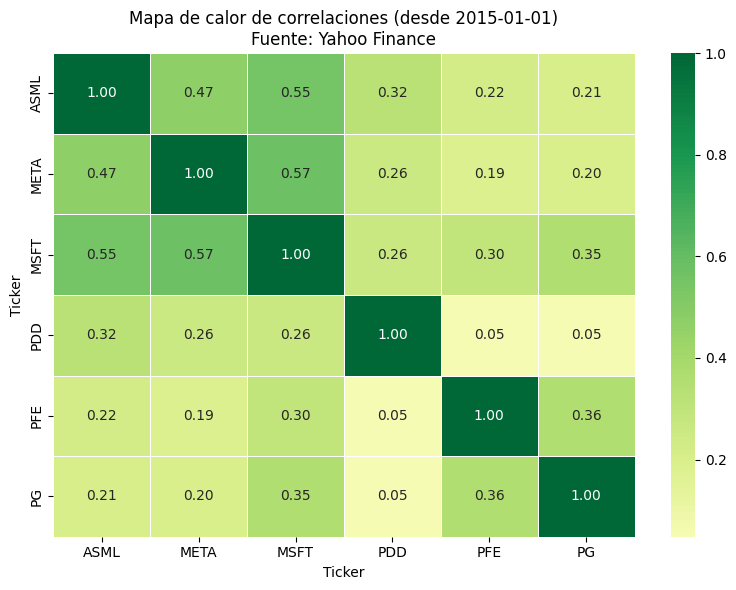

In [5]:
# Correlación de retornos diarios desde 2015
tickers_corr = ["MSFT", "ASML", "PDD", "META", "PFE", "PG"]  # ajustá esta lista a tus necesidades
start_date = "2015-01-01"
fuente_precio = "Yahoo Finance"
panel = yf.download(tickers_corr, start=start_date, auto_adjust=False, progress=False)
if isinstance(panel.columns, pd.MultiIndex):
    precios = panel.xs("Adj Close", axis=1, level=0)
else:
    precios = panel.get("Adj Close", pd.DataFrame())
if isinstance(precios, pd.Series):
    precios = precios.to_frame()
if precios.empty:
    datos_individuales = []
    for tick in tickers_corr:
        serie_panel = yf.download(tick, start=start_date, auto_adjust=False, progress=False)
        if isinstance(serie_panel, pd.DataFrame) and "Adj Close" in serie_panel.columns:
            datos_individuales.append(serie_panel["Adj Close"].rename(tick))
    if datos_individuales:
        precios = pd.concat(datos_individuales, axis=1)
    else:
        rng = pd.date_range(start_date, periods=750, freq="B")
        rng_seed = abs(hash(tuple(tickers_corr))) % (2**32)
        rng_state = np.random.default_rng(rng_seed)
        precios = pd.DataFrame(
            rng_state.lognormal(mean=0.0002, sigma=0.01, size=(len(rng), len(tickers_corr))).cumprod(axis=0),
            index=rng,
            columns=tickers_corr
        )
        fuente_precio = "Serie simulada (sin datos descargados)"
if precios.empty:
    print("No se recuperaron precios ni se pudo generar una serie alternativa.")
else:
    retornos = precios.pct_change().dropna(how="all")
    if retornos.empty:
        print("Sin retornos calculables; revisá los datos descargados.")
    else:
        corr = retornos.corr().round(3)
        styled_corr = (
            corr.style
            .background_gradient(cmap="RdYlGn")
            .format("{:.3f}")
            .set_caption(f"Correlación diaria de retornos desde {start_date} | Fuente: {fuente_precio}")
        )
        display(styled_corr)
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0, ax=ax, linewidths=0.5)
        ax.set_title(f"Mapa de calor de correlaciones (desde {start_date})\nFuente: {fuente_precio}")
        plt.tight_layout()
        display(fig)
        plt.close(fig)

In [6]:

# ============================================================
#  GENERADOR DE PDF - FICHAS DE EMPRESAS
#  Descripcion, lineas de negocio, fundacion y top accionistas
# ============================================================
try:
    from fpdf import FPDF
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "fpdf2", "-q"])
    from fpdf import FPDF

import yfinance as yf
import pandas as pd
import numpy as np
import os, re
from datetime import datetime

OUTPUT_PDF = os.path.join(
    os.path.dirname(os.path.abspath("__file__")),
    "Fichas_Empresas_Salud_Farma.pdf"
)

FONT_REG  = r"C:\Windows\Fonts\arial.ttf"
FONT_BOLD = r"C:\Windows\Fonts\arialbd.ttf"
FONT_ITAL = r"C:\Windows\Fonts\ariali.ttf"
FNAME     = "Arial"

C_HEAD   = (30,  58, 138)
C_SUB    = (30,  64, 175)
C_TITLE  = (17,  24,  39)
C_ROW1   = (239, 246, 255)
C_ROW2   = (255, 255, 255)
C_ACCENT = (37,  99, 235)
C_GREEN  = (22,  163,  74)
C_GRAY   = (107, 114, 128)

SECTOR_NAME = "Salud / Farmaceutica / Biotech"

# ── Helpers ─────────────────────────────────────────────────

def _safe(x, fallback="N/D"):
    if x is None:
        return fallback
    try:
        if isinstance(x, float) and np.isnan(x):
            return fallback
    except Exception:
        pass
    s = str(x).strip()
    return s if s else fallback

def _get_founded(info, summary):
    for k in ("founded", "foundedYear", "Founded", "yearFounded"):
        v = info.get(k)
        if v:
            return str(v)
    if summary:
        m = re.search(
            r'(?:founded|incorporated|established|organized|formed)\s+(?:in\s+)?(\d{4})',
            summary, re.IGNORECASE
        )
        if m:
            return m.group(1)
    return "No disponible"

def _get_holders(t):
    """
    Returns list of (holder_name, pct_str) for the top 3 holders.
    Tries institutional holders first, then mutual fund holders.
    """
    results = []
    for src_fn in (lambda: t.institutional_holders, lambda: t.mutualfund_holders):
        try:
            df = src_fn()
            if df is None or df.empty:
                continue
            # Detect percent column
            pct_col = None
            for candidate in ("% Out", "pctHeld", "Percent Held", "% Held"):
                if candidate in df.columns:
                    pct_col = candidate
                    break
            holder_col = "Holder" if "Holder" in df.columns else df.columns[0]
            if pct_col is None:
                # Fallback: use second numeric col
                num_cols = df.select_dtypes(include="number").columns.tolist()
                if num_cols:
                    pct_col = num_cols[0]
            if pct_col is None:
                continue
            df2 = df[[holder_col, pct_col]].copy()
            df2[pct_col] = pd.to_numeric(df2[pct_col], errors="coerce")
            df2 = df2.dropna(subset=[pct_col]).nlargest(3, pct_col)
            for _, row in df2.iterrows():
                name_h = _safe(row[holder_col])
                pct_v  = float(row[pct_col])
                # Values can be 0.07 (7%) or 7.0 (7%) depending on version
                pct_str = f"{pct_v*100:.2f}%" if pct_v < 1.5 else f"{pct_v:.2f}%"
                results.append((name_h, pct_str))
            if results:
                break
        except Exception:
            continue
    if not results:
        results = [("Informacion no disponible", "--")]
    return results[:3]

def fetch_data(sym):
    t    = yf.Ticker(sym)
    info = t.info or {}
    name     = _safe(info.get("longName") or info.get("shortName"), sym)
    sector   = _safe(info.get("sector"))
    industry = _safe(info.get("industry"))
    country  = _safe(info.get("country"))
    website  = _safe(info.get("website"))
    employees = info.get("fullTimeEmployees")
    emp_str  = f"{int(employees):,}".replace(",", ".") if employees else "N/D"
    summary  = _safe(info.get("longBusinessSummary"), "")
    # Trim to ~700 chars
    if len(summary) > 720:
        summary = summary[:717] + "..."
    founded  = _get_founded(info, summary)
    holders  = _get_holders(t)
    return {
        "ticker":    sym,
        "name":      name,
        "sector":    sector,
        "industry":  industry,
        "country":   country,
        "website":   website,
        "employees": emp_str,
        "summary":   summary,
        "founded":   founded,
        "holders":   holders,
    }

# ── PDF Class ────────────────────────────────────────────────

class FichasPDF(FPDF):
    def _sf(self, style="", size=10):
        self.set_font(FNAME, style, size)

    def header(self):
        if self.page_no() == 1:
            return
        self.set_fill_color(*C_HEAD)
        self.rect(0, 0, 210, 12, "F")
        self._sf("B", 8)
        self.set_text_color(255, 255, 255)
        self.set_xy(8, 2)
        self.cell(0, 8, f"FICHAS DE EMPRESAS  -  {SECTOR_NAME.upper()}")
        self.set_text_color(0, 0, 0)
        self.set_y(14)

    def footer(self):
        if self.page_no() == 1:
            return
        self.set_y(-10)
        self._sf("I", 7)
        self.set_text_color(150, 150, 150)
        self.cell(0, 6,
            f"Generado: {datetime.now().strftime('%d/%m/%Y %H:%M')}  |  Fuente: Yahoo Finance  |  Pag. {self.page_no()}",
            align="C")
        self.set_text_color(0, 0, 0)

    def cover_page(self, n):
        self.set_fill_color(*C_HEAD)
        self.rect(0, 0, 210, 297, "F")
        self.set_fill_color(*C_ACCENT)
        self.rect(0, 115, 210, 5, "F")
        self.set_text_color(255, 255, 255)
        self._sf("B", 32)
        self.set_xy(0, 65)
        self.cell(210, 14, "FICHAS DE EMPRESAS", align="C")
        self._sf("B", 17)
        self.set_xy(0, 88)
        self.cell(210, 10, f"Sector: {SECTOR_NAME}", align="C")
        self._sf("", 11)
        self.set_xy(0, 127)
        self.cell(210, 8, f"{n} empresas/tickers analizados", align="C")
        self._sf("", 9)
        self.set_xy(20, 145)
        self.multi_cell(170, 6,
            "Cada ficha incluye: nombre completo, descripcion del negocio, "
            "principales lineas de actividad, anio de fundacion, pais, "
            "numero de empleados y los 3 principales accionistas institucionales.",
            align="C")
        self._sf("I", 9)
        self.set_xy(0, 205)
        self.cell(210, 6, f"Generado el {datetime.now().strftime('%d/%m/%Y')}  |  Fuente: Yahoo Finance", align="C")
        self.set_text_color(0, 0, 0)

    def ticker_card(self, d):
        self.add_page()

        # ── Cabecera ticker ─────────────────────────────────
        self.set_fill_color(*C_HEAD)
        self.rect(0, 14, 210, 20, "F")
        # Ticker grande
        self._sf("B", 20)
        self.set_text_color(255, 255, 255)
        self.set_xy(8, 16)
        self.cell(35, 10, d["ticker"])
        # Nombre
        self._sf("B", 11)
        self.set_xy(45, 16)
        name_disp = d["name"][:60] if len(d["name"]) > 60 else d["name"]
        self.cell(0, 10, name_disp)
        # Sector / pais / empleados
        self._sf("I", 8)
        self.set_text_color(180, 210, 255)
        self.set_xy(45, 26)
        details = f"{d['sector']}  |  {d['industry']}  |  {d['country']}  |  Empleados: {d['employees']}"
        if len(details) > 90:
            details = details[:87] + "..."
        self.cell(0, 6, details)
        self.set_text_color(0, 0, 0)
        self.set_y(40)

        def section(title, body, bg=C_ROW1):
            if self.get_y() > 260:
                self.add_page()
            y0 = self.get_y()
            self.set_fill_color(*bg)
            self.rect(10, y0, 190, 6.5, "F")
            self._sf("B", 9)
            self.set_text_color(*C_SUB)
            self.set_xy(12, y0 + 0.5)
            self.cell(0, 5.5, title)
            self.set_text_color(*C_TITLE)
            self._sf("", 9)
            self.set_xy(12, self.get_y() + 6.5)
            self.multi_cell(186, 5.5, body if body else "No disponible.")
            self.ln(3)

        # Fundacion
        section("Fundacion", f"Anio de fundacion: {d['founded']}  |  Pais: {d['country']}")

        # Descripcion
        section(
            "Descripcion y principales lineas de negocio",
            d["summary"] if d["summary"] else "Informacion no disponible.",
            bg=C_ROW2
        )

        # Accionistas
        holders_lines = []
        for i, (h_name, h_pct) in enumerate(d["holders"], 1):
            holders_lines.append(f"{i}.  {h_name}   ({h_pct})")
        section(
            "Top 3 accionistas institucionales",
            "\n".join(holders_lines),
            bg=C_ROW1
        )

        # Web (si disponible)
        if d["website"] and d["website"] != "N/D":
            self._sf("I", 8)
            self.set_text_color(*C_GRAY)
            self.set_xy(12, self.get_y())
            self.cell(0, 5, f"Web: {d['website']}")
            self.set_text_color(0, 0, 0)

# ── Generar PDF ──────────────────────────────────────────────
pdf = FichasPDF(orientation="P", unit="mm", format="A4")
pdf.set_auto_page_break(auto=True, margin=14)
pdf.set_margins(10, 14, 10)
pdf.add_font(FNAME, style="",  fname=FONT_REG)
pdf.add_font(FNAME, style="B", fname=FONT_BOLD)
pdf.add_font(FNAME, style="I", fname=FONT_ITAL)

pdf.add_page()
pdf.cover_page(len(tickers))

print(f"Descargando informacion de {len(tickers)} tickers...\n")
errors = []
for sym in tickers:
    print(f"  {sym:6s} ... ", end="", flush=True)
    try:
        data = fetch_data(sym)
        pdf.ticker_card(data)
        print(f"OK  [{data['name'][:45]}]")
    except Exception as e:
        errors.append((sym, str(e)))
        print(f"ERROR: {e}")

pdf.output(OUTPUT_PDF)
print(f"\n{'='*55}")
print(f"PDF generado en:\n   {OUTPUT_PDF}")
if errors:
    print(f"\nTickers con errores: {[e[0] for e in errors]}")


Descargando informacion de 15 tickers...

  UNH    ... OK  [UnitedHealth Group Incorporated]
  PFE    ... OK  [Pfizer Inc.]
  ABBV   ... OK  [AbbVie Inc.]
  ABT    ... OK  [Abbott Laboratories]
  AMGN   ... OK  [Amgen Inc.]
  GILD   ... OK  [Gilead Sciences, Inc.]
  LLY    ... OK  [Eli Lilly and Company]
  BMY    ... OK  [Bristol-Myers Squibb Company]
  MRK    ... OK  [Merck & Co., Inc.]
  AZN    ... OK  [AstraZeneca PLC]
  GSK    ... OK  [GSK plc]
  CVS    ... OK  [CVS Health Corporation]
  MOH    ... OK  [Molina Healthcare, Inc.]
  DHR    ... OK  [Danaher Corporation]
  IBB    ... 

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"No fundamentals data found for symbol: IBB"}}}


OK  [iShares Biotechnology ETF]

PDF generado en:
   d:\Nico@ThisHost\OneDrive\Documentos\NICOLAS\ANALISIS ECONOMICOS\StockAnlysis\Modelos argentina\Fichas_Empresas_Salud_Farma.pdf
